In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, r2_score

In [9]:
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset shape:", df.shape)

Dataset shape: (395, 33)


In [10]:

features = [
    
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X = df[features]
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 316
Testing samples: 79


In [11]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=4,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

In [12]:
results = []
trained_models = {}

for name, current_model in models.items():

    # Train the model
    current_model.fit(X_train, y_train)

    # Make predictions
    predictions = current_model.predict(X_test)

    # Evaluate the model
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "R2": r2
    })

    trained_models[name] = current_model

    print(f"\n{name}")
    print(f"MAE: {mae:.3f}")
    print(f"R2: {r2:.3f}")


Linear Regression
MAE: 1.339
R2: 0.782

Decision Tree
MAE: 1.199
R2: 0.813

Random Forest
MAE: 1.051
R2: 0.872


In [13]:
comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by="MAE",
    ascending=True
)

display(comparison.round(3))

,Model,MAE,R2
2,Random Forest,1.051,0.872
1,Decision Tree,1.199,0.813
0,Linear Regression,1.339,0.782


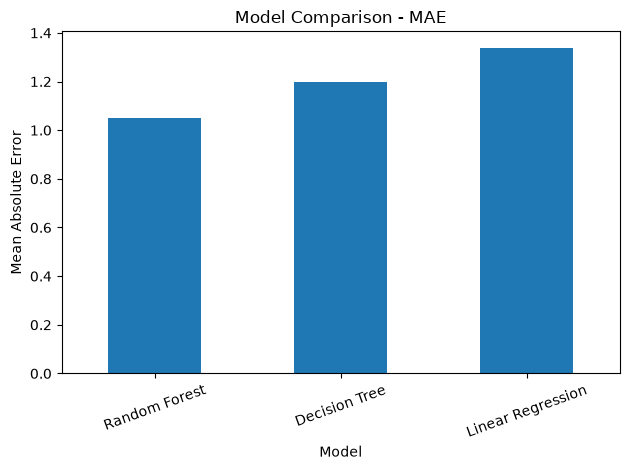

In [14]:
comparison.plot(
    x="Model",
    y="MAE",
    kind="bar",
    legend=False
)

plt.title("Model Comparison - MAE")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [15]:
new_student = pd.DataFrame([{
    "studytime": 3,
    "failures": 0,
    "absences": 2,
    "G1": 12,
    "G2": 14
}])

for name, current_model in trained_models.items():

    prediction = current_model.predict(new_student)[0]

    print(f"{name}: {prediction:.2f}/20")

Linear Regression: 13.69/20
Decision Tree: 14.12/20
Random Forest: 14.34/20


G2           0.809805
absences     0.123695
G1           0.032143
studytime    0.020026
failures     0.014331
dtype: float64

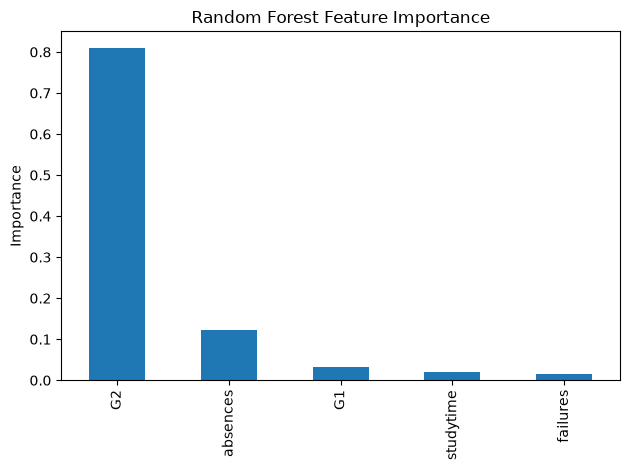

In [16]:
rf_model = trained_models["Random Forest"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

display(importance)

importance.plot(kind="bar")

plt.title("Random Forest Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()